# Percobaan : Pos Tagging

In [1]:
# !pip install nltk spacy gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 147.5 MB/s  0:00:00


In [2]:
# !python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 158.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
# import sys
# !{sys.executable} -m pip list

Package                               Version
------------------------------------- -------------------
absl-py                               2.0.0
accelerate                            1.15.0
access                                1.1.10.post3
affine                                3.0.1
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.5
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.1
altair                                5.5.0
annotated-doc                         0.0.5
annotated-types                       0.8.0
anyio                                 4.15.1
anywidget                             0.9.21
apsw                                  3.54.1.0
argon2-cffi                           25.1

In [19]:
import nltk
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [5]:
from nltk import word_tokenize,pos_tag

kalimat ="The cat sits on the mat"
tokens = word_tokenize(kalimat)
tags = pos_tag(tokens)
print(tags)

[('The', 'DT'), ('cat', 'NN'), ('sits', 'VBZ'), ('on', 'IN'), ('the', 'DT'), ('mat', 'NN')]


In [6]:
import spacy
nlp = spacy.load("en_core_web_sm")

doc = nlp(kalimat)
for token in doc:
  print(token.text,token.pos_)

The DET
cat NOUN
sits VERB
on ADP
the DET
mat NOUN


# Latihan : Pos Tagging

In [ ]:
# !pip install nltk spacy gensim
# !python -m spacy download en_core_web_sm

In [ ]:
# import sys
# !{sys.executable} -m pip list

In [71]:
import nltk
import spacy

nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

text = "Students read interesting books every morning"

tokens = nltk.word_tokenize(text)
nltk_tags = nltk.pos_tag(tokens)
nltk_nouns = [word for word, tag in nltk_tags if tag.startswith('NN')]

nlp = spacy.load("en_core_web_sm")
doc = nlp(text)
spacy_tags = [(token.text, token.pos_) for token in doc]
spacy_nouns = [token.text for token in doc if token.pos_ in ['NOUN', 'PROPN']]

print(f"{'Kata':<15} | {'NLTK Tag':<10} | {'spaCy Tag':<10}")
print("=" * 42)
for (w_nltk, n_tag), (_, s_tag) in zip(nltk_tags, spacy_tags):
    print(f"{w_nltk:<15} | {n_tag:<10} | {s_tag:<10}")

print("\n" + "=" * 42)
print(f"Jumlah Noun (NLTK)  : {len(nltk_nouns)} -> {nltk_nouns}")
print(f"Jumlah Noun (spaCy) : {len(spacy_nouns)} -> {spacy_nouns}")

Kata            | NLTK Tag   | spaCy Tag 
Students        | NNS        | NOUN      
read            | VBP        | VERB      
interesting     | VBG        | ADJ       
books           | NNS        | NOUN      
every           | DT         | DET       
morning         | NN         | NOUN      

Jumlah Noun (NLTK)  : 3 -> ['Students', 'books', 'morning']
Jumlah Noun (spaCy) : 3 -> ['Students', 'books', 'morning']


Jumlah Kata Benda (NOUN / NN) Terdapat 3 kata benda dalam kalimat tersebut yaitu Students,books,morning. Baik NLTK maupun spaCy sama-sama mendeteksi 3 kata benda yang sama.

Terdapat perbedan label,karena NLTK secara standar menggunakan Penn Treebank Tagset yang bersifat fine-grained (sangat detail). NLTK membedakan bentuk gramatikal secara rinci,seperti
- NN = Kata benda tunggal (singular)
- NNS = Kata benda jamak (plural)
- VBP = Kata kerja bentuk present non-3rd person
- VBG = Kata kerja bentuk -ing (participle/gerund)

Sedangkan spaCy secara standar menampilkan Universal POS (UPOS) Tags yang bersifat coarse-grained (lebih umum/sederhana), seperti NOUN, VERB, ADJ, dan DET.


# Percobaan : Word2Vec

In [8]:
from gensim.models import Word2Vec
# korpus: daftar jalinat, tiap kalimat daftar kata
korpus = [["kucing","suka","ikan"],
          ["anjing","suka","tulang"],
          ["kucing","dan","anjing","hewan"]]

model = Word2Vec(korpus,vector_size=100,
                 window=5,min_count=1,sg=1)

In [9]:
# vektor sebuah kata
model.wv["kucing"]

array([ 9.4563962e-05,  3.0773198e-03, -6.8126451e-03, -1.3754654e-03,
        7.6685809e-03,  7.3464094e-03, -3.6732971e-03,  2.6427018e-03,
       -8.3171297e-03,  6.2054861e-03, -4.6373224e-03, -3.1641065e-03,
        9.3113566e-03,  8.7338570e-04,  7.4907029e-03, -6.0740625e-03,
        5.1605068e-03,  9.9228229e-03, -8.4573915e-03, -5.1356913e-03,
       -7.0648370e-03, -4.8626517e-03, -3.7785638e-03, -8.5361991e-03,
        7.9556061e-03, -4.8439382e-03,  8.4236134e-03,  5.2625705e-03,
       -6.5500261e-03,  3.9578713e-03,  5.4701497e-03, -7.4265362e-03,
       -7.4057197e-03, -2.4752307e-03, -8.6257253e-03, -1.5815723e-03,
       -4.0343284e-04,  3.2996845e-03,  1.4418805e-03, -8.8142155e-04,
       -5.5940580e-03,  1.7303658e-03, -8.9737179e-04,  6.7936908e-03,
        3.9735902e-03,  4.5294715e-03,  1.4343059e-03, -2.6998555e-03,
       -4.3668128e-03, -1.0320747e-03,  1.4370275e-03, -2.6460087e-03,
       -7.0737829e-03, -7.8053069e-03, -9.1217868e-03, -5.9351693e-03,
      

In [10]:
#kata paling mirip
model.wv.most_similar("kucing")

[('dan', 0.17018885910511017),
 ('ikan', 0.145950585603714),
 ('tulang', 0.06408978998661041),
 ('hewan', -0.013514922931790352),
 ('suka', -0.023671654984354973),
 ('anjing', -0.05234673619270325)]

In [11]:
#kemiripan dua kata
model.wv.similarity("kucing","anjing")

np.float32(-0.052346732)

In [12]:
model.wv.most_similar(
    positive=["kucing","anjing"],
    negative=["hewan"]
)
model.save("w2v.model")
Word2Vec.load("w2v.model")

In [13]:
# Muat model pra-latih
import gensim.downloader as api
wv = api.load(
    "word2vec-google-news-300")
wv.most_similar("king")

[==================================================] 100.0% 1662.8/1662.8MB downloaded


[('kings', 0.7138045430183411),
 ('queen', 0.6510956883430481),
 ('monarch', 0.6413194537162781),
 ('crown_prince', 0.6204220056533813),
 ('prince', 0.6159993410110474),
 ('sultan', 0.5864824056625366),
 ('ruler', 0.5797567367553711),
 ('princes', 0.5646552443504333),
 ('Prince_Paras', 0.5432944297790527),
 ('throne', 0.5422105193138123)]

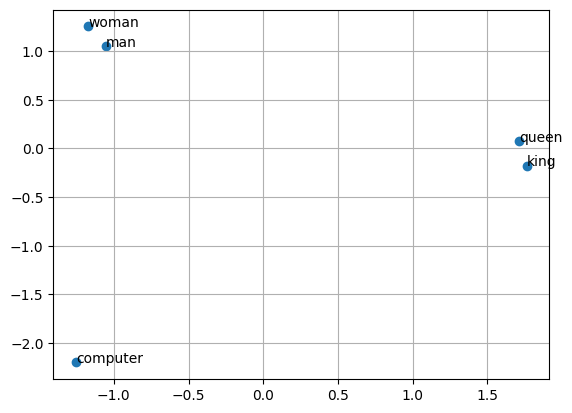

In [18]:
# from sklearn.decomposition import PCA
# import matplotlib.pyplot as plt
# xy = PCA(2).fit_transform(vektor)
# plt.scatter(xy[:,0],xy[:,1])

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

words = ["king", "queen", "man", "woman", "computer"]

vektor = [wv[w] for w in words]

xy = PCA(2).fit_transform(vektor)
plt.scatter(xy[:, 0], xy[:, 1])

for i, word in enumerate(words):
  plt.annotate(word, xy=(xy[i, 0], xy[i, 1]))

plt.grid(True)
plt.show()

# Latihan : Word2Vec

In [21]:
import gensim.downloader as api

wv = api.load("word2vec-google-news-300")

In [24]:
hasil_computer = wv.most_similar("computer", topn=5)

print("5 kata paling mirip dengan 'computer':")
for kata, skor in hasil_computer:
  print(f"- {kata}: {skor:.4f}")

5 kata paling mirip dengan 'computer':
- computers: 0.7979
- laptop: 0.6640
- laptop_computer: 0.6549
- Computer: 0.6473
- com_puter: 0.6082


In [80]:
hasil_kapital = wv.most_similar(
    positive=["Paris", "italy"], negative=["france"], topn=1
)
print("Hasil Analogi ('Paris' - 'France' + 'Italy'):", hasil_kapital)

hasil_kecil = wv.most_similar(
    positive=["paris", "italy"], negative=["france"], topn=1
)
print("Hasil Analogi ('paris' - 'france' + 'italy'):", hasil_kecil)

Hasil Analogi ('Paris' - 'France' + 'Italy'): [('Rome', 0.5483173131942749)]
Hasil Analogi ('paris' - 'france' + 'italy'): [('lohan', 0.5069674849510193)]


Jika menggunakan huruf kapital ("Paris" - "France" + "Italy") maka akan menghasilkan output "Rome". Namun, jika menggunakan huruf kecil ("paris"), hasilnya adalah "lohan".

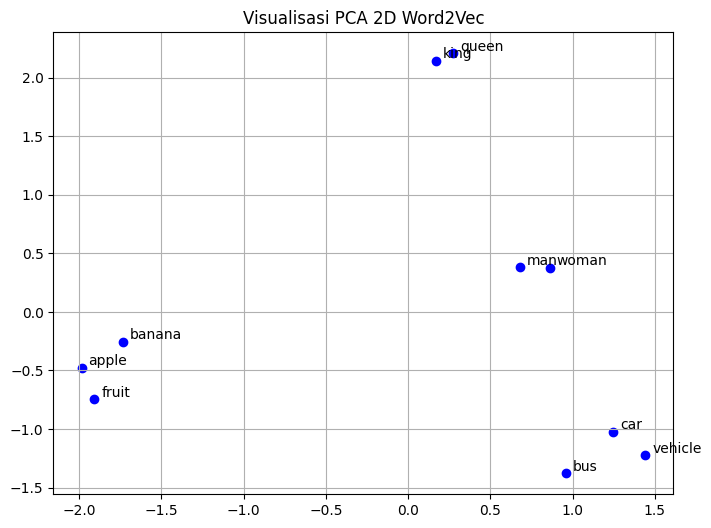

In [60]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

kata_pilihan = [
    "king",
    "queen",
    "man",
    "woman",
    "apple",
    "banana",
    "fruit",
    "car",
    "bus",
    "vehicle",
]

vektor = [wv[w] for w in kata_pilihan]

xy = PCA(n_components=2).fit_transform(vektor)

plt.figure(figsize=(8, 6))
plt.scatter(xy[:, 0], xy[:, 1], color="blue")

for i, word in enumerate(kata_pilihan):
  plt.annotate(
      word,
      xy=(xy[i, 0], xy[i, 1]),
      xytext=(5, 2),
      textcoords="offset points",
  )

plt.title("Visualisasi PCA 2D Word2Vec")
plt.grid(True)
plt.show()

Hasil Pengamatan terdapat pengelompokan cluster dari kata-kata yang memiliki kategori yang sama seperti:   
- cat, dog, dan lion berkumpul dalam satu wilayah (hewan).
- car, truck, dan bus berkumpul di wilayah terpisah (transportasi).
- apple, banana, orange, dan fruit berada di wilayah tersendiri (buah/makanan).

Meskipun PCA memotong dimensi vektor dari 300 menjadi 2 dimensi, jarak dan
kemiripan semantik antar-kata tetap dapat terwakili dengan baik di dalam grafik.   